In [3]:
import os
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (f1_score, confusion_matrix,
                             classification_report, accuracy_score)
import joblib
import wandb
import warnings
warnings.filterwarnings("ignore")

In [4]:
# --- 1. Setup ---
ROOT = '../data/messy_mashup'
STEMS_PATH = os.path.join(ROOT, 'genres_stems')
GENRES = ["blues", "classical", "country", "disco", "hiphop",
          "jazz", "metal", "pop", "reggae", "rock"]

MODEL_DIR = '../models'
os.makedirs(MODEL_DIR, exist_ok=True)

In [5]:
def extract_features(song_path):
    """Extract audio features from other.wav stem."""
    y, sr = librosa.load(os.path.join(song_path, 'other.wav'), sr=22050, duration=10)
    tempo, _ = librosa.beat.beat_track(y=y, sr=sr)
    spec_cent = np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))
    zcr = np.mean(librosa.feature.zero_crossing_rate(y))
    rolloff = np.mean(librosa.feature.spectral_rolloff(y=y, sr=sr))
    return [float(tempo), spec_cent, zcr, rolloff]

In [6]:
# --- 2. Data Preparation & Stratified Split ---
data = []
for g in GENRES:
    gp = os.path.join(STEMS_PATH, g)
    songs = sorted([s for s in os.listdir(gp) if os.path.isdir(os.path.join(gp, s))])
    for s in songs[:50]:
        data.append({'path': os.path.join(gp, s), 'genre': g})

df = pd.DataFrame(data)
train_df, val_df = train_test_split(df, test_size=0.2, stratify=df['genre'], random_state=42)

In [7]:
print("Extracting training features...")
X_train = np.array([extract_features(p) for p in train_df['path']])
y_train = train_df['genre'].values

print("Extracting validation features...")
X_val = np.array([extract_features(p) for p in val_df['path']])
y_val = val_df['genre'].values

feature_names = ['tempo', 'spectral_centroid', 'zcr', 'spectral_rolloff']

Extracting training features...
Extracting validation features...


In [8]:
# --- 3. WandB Init ---
wandb.init(
    project="21f3002298-dl-genai-project",
    name="decision-tree-baseline",
    config={
        "model": "DecisionTreeClassifier",
        "max_depth": 5,
        "random_state": 42,
        "features": feature_names,
        "stem_used": "other.wav",
        "audio_duration": 10,
        "sample_rate": 22050,
        "train_size": len(X_train),
        "val_size": len(X_val),
        "n_genres": len(GENRES),
        "songs_per_genre": 50,
    }
)

wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.
wandb: Paste your API key and hit enter:wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: C:\Users\Atul\_netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


In [9]:
# --- 4. Model Training ---
clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [10]:
# --- 5. Predictions and Evaluation ---
y_pred = clf.predict(X_val)
macro_f1 = f1_score(y_val, y_pred, average='macro')
acc = accuracy_score(y_val, y_pred)
cm = confusion_matrix(y_val, y_pred, labels=GENRES)
cr = classification_report(y_val, y_pred, labels=GENRES, output_dict=True)
cr_text = classification_report(y_val, y_pred, labels=GENRES)

In [ ]:
print(f"Validation Macro F1 Score: {macro_f1:.4f}")
print(f"Model Accuracy: {acc:.4f}\n")
print("Detailed Classification Report:")
print(cr_text)

Validation Macro F1 Score: 0.1523
Model Accuracy: 0.2000

Detailed Classification Report:
              precision    recall  f1-score   support

       blues       0.43      0.30      0.35        10
   classical       0.00      0.00      0.00        10
     country       0.12      0.20      0.15        10
       disco       0.21      0.70      0.33        10
      hiphop       0.00      0.00      0.00        10
        jazz       0.08      0.10      0.09        10
       metal       0.38      0.30      0.33        10
         pop       0.00      0.00      0.00        10
      reggae       0.20      0.40      0.27        10
        rock       0.00      0.00      0.00        10

    accuracy                           0.20       100
   macro avg       0.14      0.20      0.15       100
weighted avg       0.14      0.20      0.15       100



In [12]:
# --- 6. Log metrics to WandB ---
wandb.log({
    "val_macro_f1": macro_f1,
    "val_accuracy": acc,
})

In [13]:
# Log per-genre precision, recall, f1
for genre in GENRES:
    if genre in cr:
        wandb.log({
            f"{genre}_precision": cr[genre]['precision'],
            f"{genre}_recall": cr[genre]['recall'],
            f"{genre}_f1": cr[genre]['f1-score'],
        })

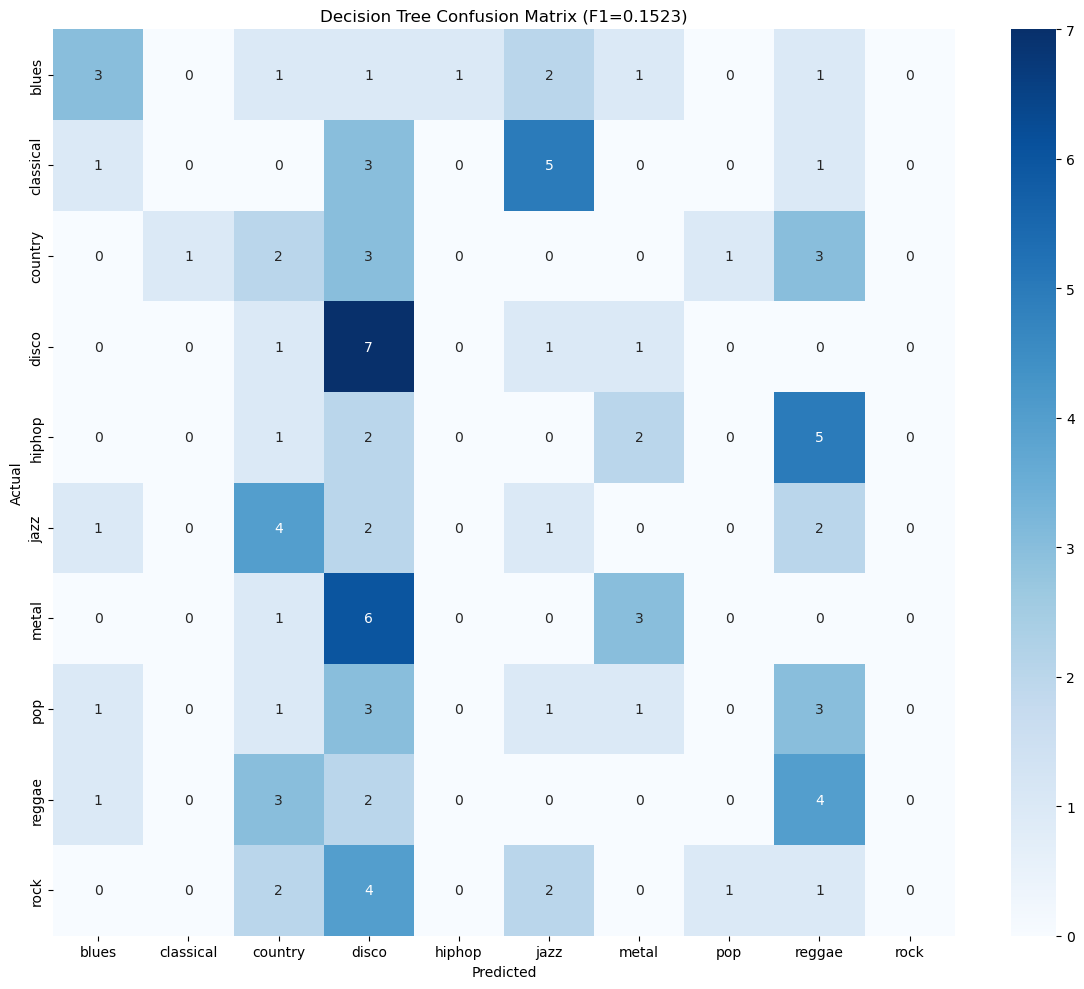

In [14]:
# --- 7. Confusion Matrix Visualization ---
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=GENRES, yticklabels=GENRES, ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(f'Decision Tree Confusion Matrix (F1={macro_f1:.4f})')
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'dt_confusion_matrix.png'), dpi=150)
wandb.log({"confusion_matrix": wandb.Image(fig)})
plt.show()

In [15]:
# --- 8. TP, TN, FP, FN per genre ---
print(f"\n{'Genre':<12} {'TP':>5} {'FP':>5} {'FN':>5} {'TN':>5}")
tp_dict, fn_dict = {}, {}
for i, genre in enumerate(GENRES):
    tp = cm[i, i]
    fp = cm[:, i].sum() - tp
    fn = cm[i, :].sum() - tp
    tn = cm.sum() - tp - fp - fn
    tp_dict[genre] = tp
    fn_dict[genre] = fn
    print(f"{genre:<12} {tp:>5} {fp:>5} {fn:>5} {tn:>5}")
    wandb.log({f"{genre}_TP": tp, f"{genre}_FP": fp, f"{genre}_FN": fn, f"{genre}_TN": tn})


Genre           TP    FP    FN    TN
blues            3     4     7    86
classical        0     1    10    89
country          2    14     8    76
disco            7    26     3    64
hiphop           0     1    10    89
jazz             1    11     9    79
metal            3     5     7    85
pop              0     2    10    88
reggae           4    16     6    74
rock             0     0    10    90


In [16]:
highest_tp = max(tp_dict, key=tp_dict.get)
lowest_fn = min(fn_dict, key=fn_dict.get)
print(f"\nGenre with highest TP: {highest_tp} (TP={tp_dict[highest_tp]})")
print(f"Genre with lowest FN: {lowest_fn} (FN={fn_dict[lowest_fn]})")


Genre with highest TP: disco (TP=7)
Genre with lowest FN: disco (FN=3)


In [17]:
# --- 9. Save model and feature config ---
model_path = os.path.join(MODEL_DIR, 'decision_tree_baseline.pkl')
joblib.dump({
    'model': clf,
    'feature_names': feature_names,
    'genres': GENRES,
    'params': {
        'sr': 22050,
        'duration': 10,
        'stem': 'other.wav',
        'max_depth': 5,
    }
}, model_path)
print(f"\nModel saved to {model_path}")


Model saved to ../models\decision_tree_baseline.pkl


In [18]:
# Log model artifact to WandB
artifact = wandb.Artifact('decision-tree-baseline', type='model')
artifact.add_file(model_path)
wandb.log_artifact(artifact)

wandb.finish()

blues_FN,▁
blues_FP,▁
blues_TN,▁
blues_TP,▁
blues_f1,▁
blues_precision,▁
blues_recall,▁
classical_FN,▁
classical_FP,▁
classical_TN,▁
+62,...


## The End